# Week 3: Pattern-scaling emulator for ClimateBench

Pattern scaling is the reference point for the other baselines: anything more complex has to beat it. Each grid cell's
response is a straight line in global-mean temperature,

$$y_\text{cell}(t) = a_\text{cell} + b_\text{cell}\, T_\text{global}(t),$$

fit separately for each target and cell on the training scenarios.

The model never says where the test-time $T_\text{global}$ comes from, and that choice decides what the score means.
Two versions:

- **A. Oracle $T$ (as in the paper).** $T_\text{global}$ for `ssp245` is the *true* `ssp245` ensemble-mean global
  temperature, smoothed with a 10-year rolling mean. The model is given the global trajectory and only has to predict the
  pattern. This version should reproduce the published row.
- **B. $T$ predicted from the forcings.** A one-box energy-balance model, fit on the training scenarios only, predicts
  $T_\text{global}$ from CO2, CH4, SO2 and BC. This is the fair comparison with the GP, RF and CNN-LSTM, which only see the forcings.

Run with the **Python (jcm)** kernel (`environment.yml`).

| | |
|---|---|
| **Train** | historical, hist-GHG, hist-aer, ssp126, ssp370, ssp585 (ensemble means) |
| **Test** | ssp245 (version A uses its global-mean `tas` as input; nothing else from ssp245 is used for fitting) |
| **Inputs** | A: smoothed true $T_\text{global}$. B: cumulative CO2, CH4, global-mean SO2 and BC emissions |
| **Targets** | tas, diurnal_temperature_range, pr, pr90: one regression per target and grid cell |

Saves `results/pattern_scaling_ssp245.nc` (A) and `results/pattern_scaling_ebm_ssp245.nc` (B) in the shared format, for
`Week3_Leaderboard.ipynb`.

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

REPO = os.path.abspath("..")          # this notebook lives in <repo>/notebooks
assert os.path.exists(f"{REPO}/metrics.py"), "run from the notebooks/ folder"
sys.path.insert(0, REPO)
from metrics import TARGETS, PERIOD, nrmse, global_mean  # shared with the other baselines

DATA = os.path.expanduser("~/data/climatebench")
FIGS = f"{REPO}/figures"
RESULTS = f"{REPO}/results"
os.makedirs(FIGS, exist_ok=True)
os.makedirs(RESULTS, exist_ok=True)

TRAIN = ["historical", "hist-GHG", "hist-aer", "ssp126", "ssp370", "ssp585"]   # same split as the GP and RF
TEST = "ssp245"
SSPS = [e for e in TRAIN + [TEST] if e.startswith("ssp")]   # these continue from historical in 2015

STYLE = {"tas": ("tas", "K", "RdBu_r"),
         "diurnal_temperature_range": ("dtr", "K", "RdBu_r"),
         "pr": ("pr", "mm/day", "BrBG"),
         "pr90": ("pr90", "mm/day", "BrBG")}

assert TEST not in TRAIN
warnings.filterwarnings("ignore", category=RuntimeWarning, module="shapely")   # harmless, from coastlines()

## 1. Load the data

Same loading as the GP notebook: ensemble means for training, precipitation converted to mm/day. The outputs are
anomalies from the pre-industrial control, so $T_\text{global}$ is a warming (K), not an absolute temperature.

In [2]:
def load_inputs(exp):
    return xr.open_dataset(f"{DATA}/inputs_{exp}.nc")


def load_outputs(exp):
    ds = xr.open_dataset(f"{DATA}/outputs_{exp}.nc")[TARGETS]
    ds["pr"] = ds["pr"] * 86400
    ds["pr90"] = ds["pr90"] * 86400
    return ds


inputs = {exp: load_inputs(exp) for exp in TRAIN + [TEST]}
outputs = {exp: load_outputs(exp) for exp in TRAIN + [TEST]}
truth = outputs[TEST].mean("member")      # ssp245 ensemble mean: what we score against

for exp in TRAIN + [TEST]:
    print(f"{exp:10s} years {int(outputs[exp].time[0])}-{int(outputs[exp].time[-1])}, "
          f"members {outputs[exp].sizes['member']}")

historical years 1850-2014, members 3
hist-GHG   years 1850-2014, members 3
hist-aer   years 1850-2014, members 3
ssp126     years 2015-2100, members 1
ssp370     years 2015-2100, members 3
ssp585     years 2015-2100, members 1
ssp245     years 2015-2100, members 3


## 2. Fit the patterns

For every target and grid cell, ordinary least squares of the cell's value on $[1, T_\text{global}]$ over all 753
training years. $T_\text{global}$ is the cos(latitude)-weighted global mean of the ensemble-mean `tas` in the same year.
All 13,824 cells share the same design matrix, so this is one `lstsq` call per target.

In [3]:
N_CELLS = 96 * 144


def gmt(exp):
    # global-mean warming of the ensemble mean, one value per year
    return global_mean(outputs[exp]["tas"].mean("member"))


T_train = np.concatenate([gmt(exp).values for exp in TRAIN])
Y_train = {var: np.concatenate([outputs[exp][var].mean("member").values.reshape(-1, N_CELLS) for exp in TRAIN])
           for var in TARGETS}
assert all(len(y) == len(T_train) for y in Y_train.values())


def fit_pattern(T, Y):
    A = np.column_stack([np.ones_like(T), T])
    coef, *_ = np.linalg.lstsq(A, Y, rcond=None)
    return coef                                   # (2, N_CELLS): intercept, slope per K of global warming


def predict_pattern(coef, T, like):
    # T: global-mean warming per test year -> maps on the grid of `like`
    maps = coef[0] + np.outer(np.asarray(T), coef[1])
    return xr.DataArray(maps.reshape(-1, 96, 144), dims=like.dims, coords=like.coords)


patterns = {var: fit_pattern(T_train, Y_train[var]) for var in TARGETS}

# sanity check: the tas pattern's area-weighted mean slope must be 1 (the global mean of tas *is* T)
slope_tas = xr.DataArray(patterns["tas"][1].reshape(96, 144), dims=["lat", "lon"],
                         coords={"lat": truth.lat, "lon": truth.lon})
print(f"global mean of the tas slope: {float(global_mean(slope_tas)):.4f} K/K")

global mean of the tas slope: 1.0000 K/K


**The patterns.** Change per K of global warming. Land warms faster than ocean and the Arctic fastest; precipitation
increases at high latitudes and in the deep tropics.

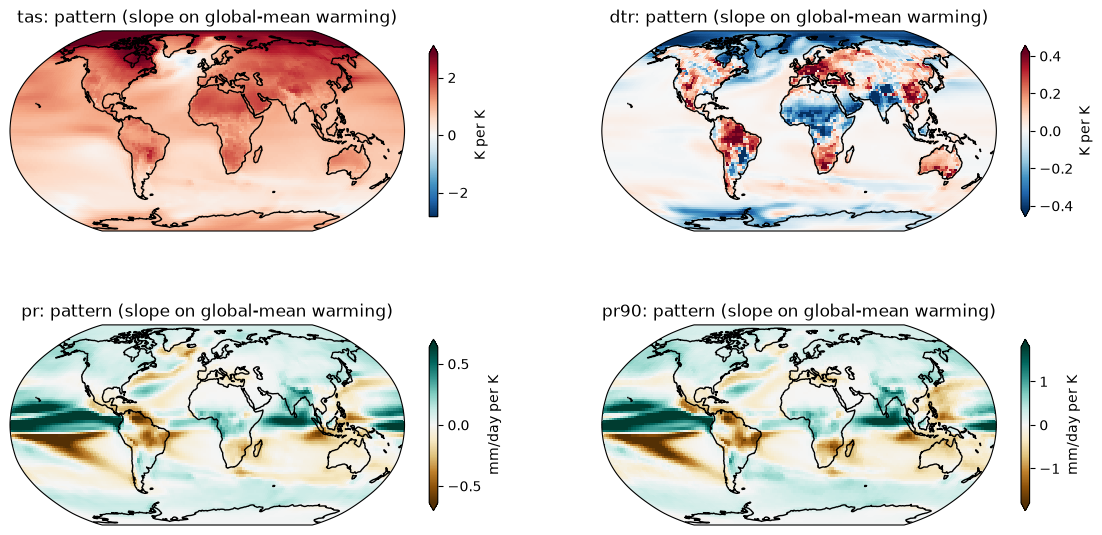

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), subplot_kw={"projection": ccrs.Robinson()})
for ax, var in zip(axes.flat, TARGETS):
    name, unit, cmap = STYLE[var]
    slope = xr.DataArray(patterns[var][1].reshape(96, 144), dims=["lat", "lon"],
                         coords={"lat": truth.lat, "lon": truth.lon})
    lim = float(np.nanpercentile(np.abs(slope), 98))
    slope.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, vmin=-lim, vmax=lim,
               cbar_kwargs={"label": f"{unit} per K", "shrink": 0.7})
    ax.coastlines()
    ax.set_title(f"{name}: pattern (slope on global-mean warming)")
fig.savefig(f"{FIGS}/week3_ps_patterns.png", dpi=150, bbox_inches="tight")

## 3. Version A: oracle $T_\text{global}$ (as in the paper)

The test-time input is the true `ssp245` ensemble-mean global temperature, with a trailing 10-year rolling mean. The window
for 2080 covers 2071–2080, so every scored year has a full window (`min_periods=1` only affects 2015–2023).

This uses the **answer** for `ssp245`: its global trajectory. The tas global NRMSE of this version is therefore only the
smoothing error, not a skill score.

In [5]:
T_true = gmt(TEST)
T_oracle = T_true.rolling(time=10, min_periods=1).mean()

pred_A = {var: predict_pattern(patterns[var], T_oracle.values, truth[var]) for var in TARGETS}

## 4. Version B: $T_\text{global}$ predicted from the forcings

**Model.** A one-box energy balance, $C\,\frac{dT}{dt} = F - \lambda T$, with the forcing $F$ linear in the inputs:

$$T(t) = c_0 + \sum_k c_k\, \tilde x_k(t), \qquad \tilde x_k(t) = \alpha\,\tilde x_k(t-1) + (1-\alpha)\, x_k(t),
\quad \alpha = e^{-1/\tau}.$$

- $x_k$: cumulative CO2 emissions, CH4, and the global-mean SO2 and BC emissions.
- $\tau = C/\lambda$ is the response timescale in years. $\tau = 0$ means no lag (plain linear regression on the inputs).
- Cumulative CO2 enters linearly because warming is close to linear in cumulative emissions (TCRE; Week 1). That linearity
  already includes the slow carbon-cycle and ocean effects that a CO2 forcing of $5.35\ln(C/C_0)$ would need a carbon-cycle
  model for.
- Aerosol and CH4 effects are fast, so they enter as (lagged) emission rates.

**History.** The SSP files start in 2015, but the lag needs the state in 2014. SSP inputs are therefore run on after the
`historical` inputs, which they continue (cumulative CO2 1500 → 1536 GtCO2). This only uses `historical` *inputs*, so no
`ssp245` output is involved.

**Fitting.** $c_k$ by least squares on the six training scenarios. $\tau$ by **leave-one-scenario-out** cross-validation
over the six training scenarios (`ssp245` is never used).

In [6]:
FORCERS = ["CO2", "CH4", "SO2", "BC"]


def forcer_series(exp):
    # one value per year per forcer; maps reduced to their area-weighted global mean
    ds = inputs[exp]
    w = np.cos(np.deg2rad(ds.latitude))
    cols = {"CO2": ds["CO2"].values, "CH4": ds["CH4"].values}
    for name in ["SO2", "BC"]:
        cols[name] = ds[name].weighted(w).mean(["latitude", "longitude"]).values
    return pd.DataFrame(cols, index=ds.time.values)


raw = {exp: forcer_series(exp) for exp in TRAIN + [TEST]}
hist = forcer_series("historical")
full = {exp: pd.concat([hist, raw[exp]]) if exp in SSPS else raw[exp] for exp in raw}

# scale each forcer by its training std so the least squares is well conditioned (SO2 is ~1e-12 kg m-2 s-1)
scale = pd.concat([raw[exp] for exp in TRAIN]).std()


def lagged(exp, tau):
    x = (full[exp] / scale).values
    if tau > 0:
        a = np.exp(-1 / tau)
        out = np.empty_like(x)
        out[0] = x[0]
        for t in range(1, len(x)):
            out[t] = a * out[t - 1] + (1 - a) * x[t]
        x = out
    x = pd.DataFrame(x, index=full[exp].index, columns=FORCERS)
    return x.loc[raw[exp].index]          # keep the experiment's own years


def fit_ebm(exps, tau):
    X = np.concatenate([lagged(e, tau).values for e in exps])
    y = np.concatenate([gmt(e).values for e in exps])
    coef, *_ = np.linalg.lstsq(np.column_stack([np.ones(len(X)), X]), y, rcond=None)
    return coef


def predict_ebm(coef, exp, tau):
    X = lagged(exp, tau).values
    return coef[0] + X @ coef[1:]


# leave-one-scenario-out CV over the training scenarios only
TAUS = [0, 1, 2, 3, 5, 8, 12, 20, 30]
cv = pd.DataFrame(index=TAUS, columns=TRAIN, dtype=float)
for tau in TAUS:
    for held in TRAIN:
        coef = fit_ebm([e for e in TRAIN if e != held], tau)
        cv.loc[tau, held] = np.sqrt(np.mean((predict_ebm(coef, held, tau) - gmt(held).values) ** 2))
cv["mean"] = cv[TRAIN].mean(axis=1)
cv.index.name = "tau (years)"
TAU = int(cv["mean"].idxmin())
print(f"chosen tau = {TAU} years")
cv.round(3)

chosen tau = 1 years


,historical,hist-GHG,hist-aer,ssp126,ssp370,ssp585,mean
tau (years),,,,,,,
0,0.159,0.192,0.216,0.173,0.176,0.170,0.181
1,0.157,0.190,0.213,0.172,0.181,0.171,0.181
2,0.155,0.187,0.210,0.170,0.191,0.175,0.181
3,0.153,0.185,0.207,0.169,0.202,0.181,0.183
5,0.148,0.182,0.202,0.169,0.224,0.196,0.187
8,0.140,0.185,0.196,0.173,0.257,0.223,0.195
12,0.135,0.194,0.190,0.180,0.297,0.256,0.209
20,0.140,0.222,0.181,0.197,0.363,0.309,0.235
30,0.149,0.249,0.176,0.219,0.421,0.357,0.262


In [7]:
ebm_coef = fit_ebm(TRAIN, TAU)
print("fitted EBM: T = c0 + sum c_k * lagged x_k, x_k in units of its training std")
print(pd.Series(ebm_coef, index=["c0"] + FORCERS).round(3).to_string())

T_ebm = xr.DataArray(predict_ebm(ebm_coef, TEST, TAU), dims=["time"], coords={"time": truth.time})
pred_B = {var: predict_pattern(patterns[var], T_ebm.values, truth[var]) for var in TARGETS}

fitted EBM: T = c0 + sum c_k * lagged x_k, x_k in units of its training std
c0     0.055
CO2    0.781
CH4    0.288
SO2   -0.199
BC    -0.011


**How well does the EBM fit the training scenarios?** Each panel is the leave-one-out prediction for that scenario
(fit on the other five), so this is out-of-sample.

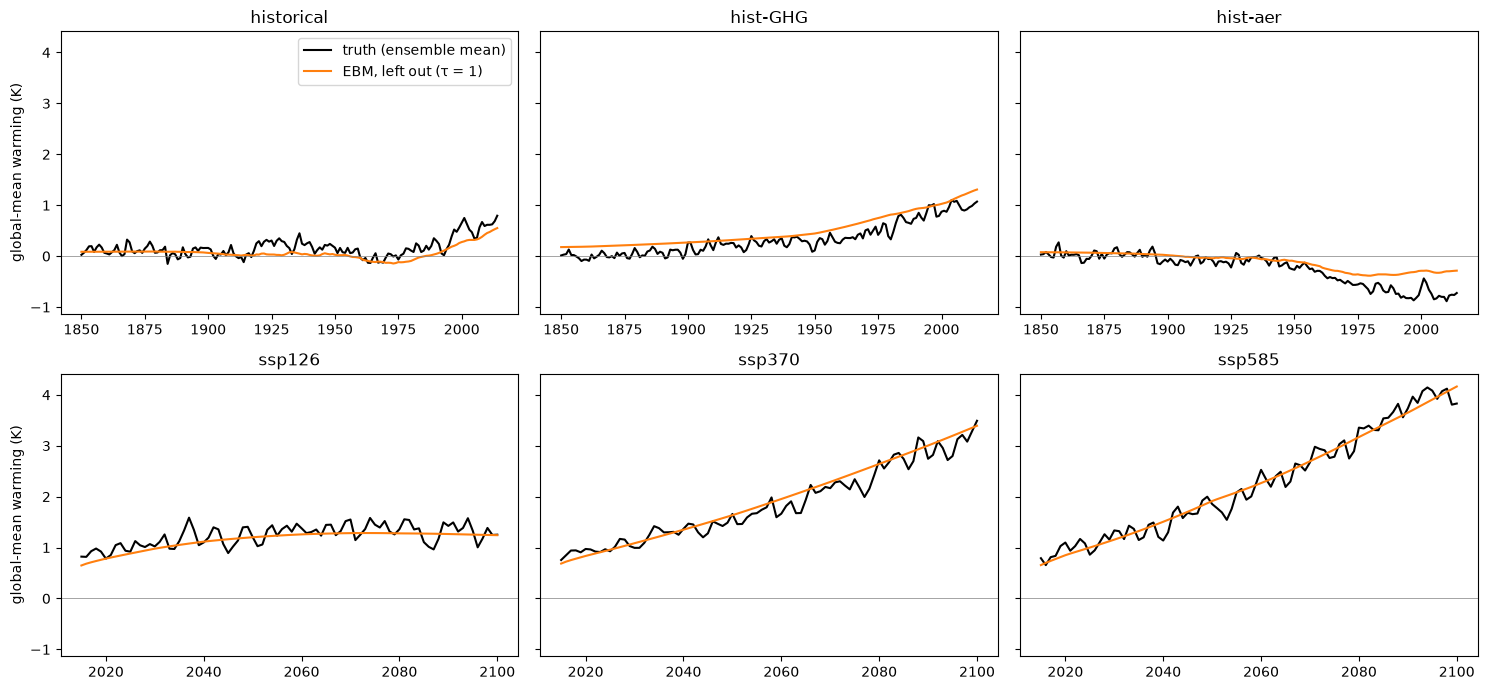

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, held in zip(axes.flat, TRAIN):
    coef = fit_ebm([e for e in TRAIN if e != held], TAU)
    ax.plot(gmt(held).time, gmt(held), color="k", label="truth (ensemble mean)")
    ax.plot(gmt(held).time, predict_ebm(coef, held, TAU), color="C1", label=f"EBM, left out (τ = {TAU})")
    ax.set_title(held)
    ax.axhline(0, color="gray", lw=0.5)
axes[0, 0].set_ylabel("global-mean warming (K)")
axes[1, 0].set_ylabel("global-mean warming (K)")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(f"{FIGS}/week3_ps_ebm_cv.png", dpi=150, bbox_inches="tight")

## 5. Leakage audit

- **Version A** uses `ssp245`'s ensemble-mean global `tas` as its input. That is the definition of the published baseline,
  not a bug, but its scores are not comparable with the emulators that only see forcings.
- **Version B** uses `ssp245` *inputs* only (plus `historical` inputs for the 2014 state). The patterns, the EBM coefficients,
  $\tau$ and the forcer scaling are all fit on the six training scenarios.
- In both versions the patterns use training data only. `truth` is used for scoring, plotting and grid coordinates.

In [9]:
assert TEST not in TRAIN
assert len(T_train) == sum(outputs[e].sizes["time"] for e in TRAIN)          # patterns: training years only
assert set(cv.columns) - {"mean"} == set(TRAIN)                               # tau: CV over training scenarios only
print("ok")

ok


## 6. Save the predictions

Shared format (see the README): the four targets as variables, dims `(time, lat, lon)`, years 2015–2100, precipitation in mm/day.

In [10]:
def to_file(maps, path, **attrs):
    ds = xr.Dataset({var: maps[var].astype(np.float32) for var in TARGETS})
    ds.attrs.update(attrs)
    ds.to_netcdf(path)


to_file(pred_A, f"{RESULTS}/pattern_scaling_ssp245.nc", model="Pattern scaling (oracle T, as in the paper)",
        notebook="Week3_PatternScaling.ipynb",
        note="test-time input is the true ssp245 ensemble-mean global tas, 10-year trailing rolling mean")
to_file(pred_B, f"{RESULTS}/pattern_scaling_ebm_ssp245.nc", model="Pattern scaling (T from a one-box EBM)",
        notebook="Week3_PatternScaling.ipynb", note=f"global-mean T predicted from forcings, tau={TAU} years")

## 7. Scores

NRMSE over 2080–2100 from `metrics.py`, next to the published pattern-scaling row (`paper_figures.ipynb`). The full table with
the other baselines is in `Week3_Leaderboard.ipynb`. (DTR's global-mean change is close to zero, so dividing by it makes DTR's
NRMSE large for every model.)

In [11]:
PUBLISHED_PS = {"tas": (0.080, 0.048, 0.320), "diurnal_temperature_range": (8.083, 2.327, 19.719),
                "pr": (2.006, 0.331, 3.662), "pr90": (2.400, 0.412, 4.461)}
METRICS = ["Spatial", "Global", "Total"]


def row(scores):
    return pd.Series({(STYLE[var][0], k): scores[var][k] for var in TARGETS for k in METRICS})


scores = pd.DataFrame({
    "Pattern scaling (published)": row({v: dict(zip(METRICS, PUBLISHED_PS[v])) for v in TARGETS}),
    "A: oracle T (ours)": row({v: nrmse(truth[v], pred_A[v]) for v in TARGETS}),
    "B: EBM T (ours)": row({v: nrmse(truth[v], pred_B[v]) for v in TARGETS}),
}).T
scores.round(3)

tas                   dtr                 \
                            Spatial Global  Total Spatial Global   Total   
Pattern scaling (published)   0.080  0.048  0.320   8.083  2.327  19.719   
A: oracle T (ours)            0.080  0.048  0.320   7.977  2.115  18.552   
B: EBM T (ours)               0.088  0.059  0.383   7.983  2.086  18.414   

                                 pr                  pr90                
                            Spatial Global  Total Spatial Global  Total  
Pattern scaling (published)   2.006  0.331  3.662   2.400  0.412  4.461  
A: oracle T (ours)            1.902  0.287  3.338   2.279  0.370  4.128  
B: EBM T (ours)               1.936  0.303  3.452   2.312  0.383  4.226

**Where the error comes from.** Global-mean warming averaged over 2080–2100, and the RMSE of the yearly series:

In [12]:
def summary(T):
    t = T.sel(time=PERIOD)
    return {"mean 2080-2100 (K)": float(t.mean()),
            "RMSE vs truth (K)": float(np.sqrt(((t - T_true.sel(time=PERIOD)) ** 2).mean()))}


pd.DataFrame({"truth": summary(T_true), "A: oracle (smoothed truth)": summary(T_oracle),
              "B: EBM": summary(T_ebm)}).T.round(3)

,mean 2080-2100 (K),RMSE vs truth (K)
truth,2.071,0.000
A: oracle (smoothed truth),2.020,0.099
B: EBM,1.982,0.122


## 8. Figures

**Global-mean warming in `ssp245`**: the three members, the ensemble mean, and the two test-time inputs.

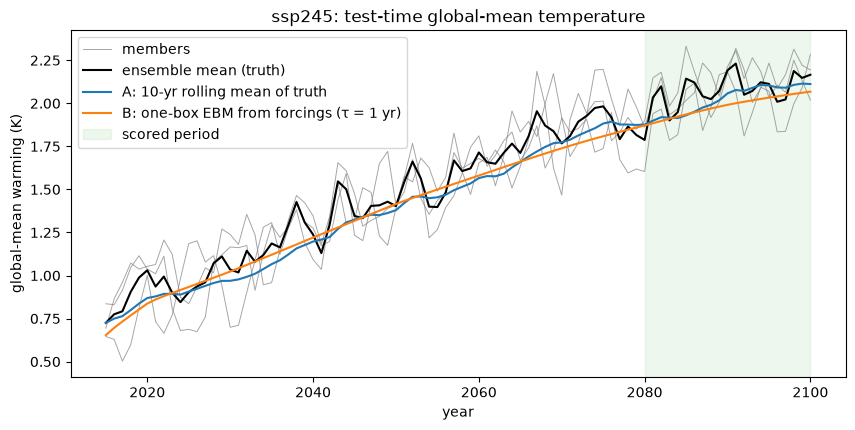

In [13]:
members = global_mean(outputs[TEST]["tas"])
fig, ax = plt.subplots(figsize=(10, 4.5))
for m in members.member.values:
    ax.plot(members.time, members.sel(member=m), color="gray", lw=0.7, alpha=0.7,
            label="members" if m == members.member.values[0] else None)
ax.plot(T_true.time, T_true, color="k", label="ensemble mean (truth)")
ax.plot(T_oracle.time, T_oracle, color="C0", label="A: 10-yr rolling mean of truth")
ax.plot(T_ebm.time, T_ebm, color="C1", label=f"B: one-box EBM from forcings (τ = {TAU} yr)")
ax.axvspan(2080, 2100, color="C2", alpha=0.08, label="scored period")
ax.set_xlabel("year")
ax.set_ylabel("global-mean warming (K)")
ax.set_title("ssp245: test-time global-mean temperature")
ax.legend()
fig.savefig(f"{FIGS}/week3_ps_global_T.png", dpi=150, bbox_inches="tight")

**Difference maps** (prediction − truth, 2080–2100 mean) for each target and version, with one colour scale per row.

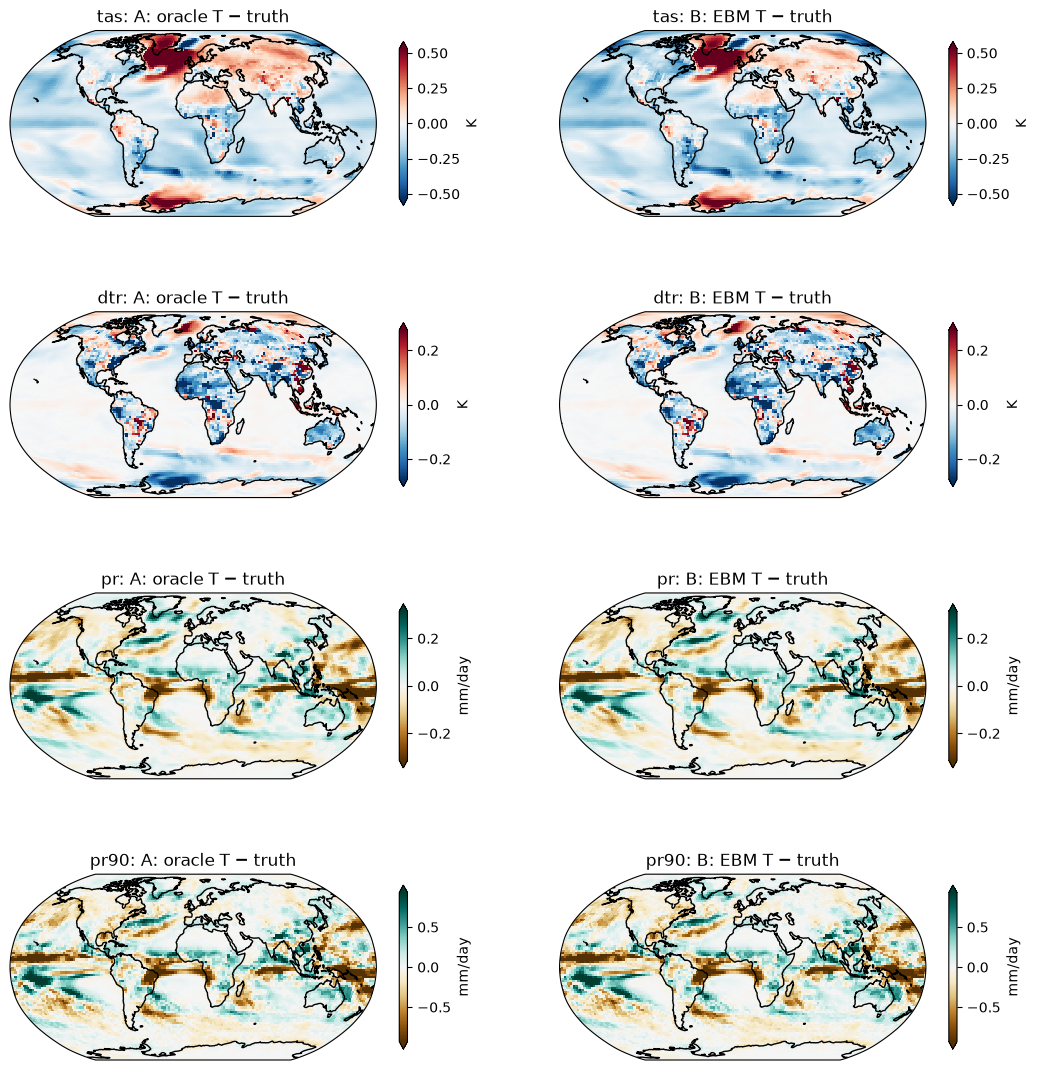

In [14]:
fig, axes = plt.subplots(4, 2, figsize=(13, 14), subplot_kw={"projection": ccrs.Robinson()})
for r, var in enumerate(TARGETS):
    name, unit, cmap = STYLE[var]
    t = truth[var].sel(time=PERIOD).mean("time")
    diffs = {"A: oracle T": pred_A[var].sel(time=PERIOD).mean("time") - t,
             "B: EBM T": pred_B[var].sel(time=PERIOD).mean("time") - t}
    lim = max(float(np.nanpercentile(np.abs(d), 98)) for d in diffs.values())
    for ax, (title, d) in zip(axes[r], diffs.items()):
        d.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, vmin=-lim, vmax=lim,
               cbar_kwargs={"label": unit, "shrink": 0.7})
        ax.coastlines()
        ax.set_title(f"{name}: {title} − truth")
fig.savefig(f"{FIGS}/week3_ps_difference_maps.png", dpi=150, bbox_inches="tight")

## 9. Comparison with the official pattern scaling

Written **after** this notebook was finished ("write your own first, then compare"), against
`baseline_models/pattern_scaling_model.ipynb`.

**Same:** one linear regression per target and grid cell on global-mean `tas`; precipitation in mm/day; the test-time input is
the `ssp245` ensemble-mean global `tas` with a trailing `rolling(10, min_periods=1)` mean (so version A uses the same "oracle"
input as the paper).

**Different:**

| # | Official | This notebook |
|---|---|---|
| 1 | Trains on **4 scenarios**: historical, ssp585, ssp126, ssp370 (no hist-GHG, hist-aer) | 6 scenarios, the team's shared split |
| 2 | **One ensemble member** per scenario (historical member 2, "the first one has some missing DTR values") | Ensemble mean |
| 3 | `LinearRegression(fit_intercept=False)`: the line goes through 0 | Intercept fitted |

**Test.** Rebuild the official setup, then change one thing at a time. All rows use the same oracle test input as version A,
so only the fitted patterns differ. These variants were run *after* seeing the `ssp245` scores, so they are diagnostics only:
version A above is not changed to whichever row scores best.

In [15]:
OFFICIAL_MEMBER = {"historical": 2, "ssp585": 1, "ssp126": 1, "ssp370": 1}   # member labels the official notebook uses
OFFICIAL_TRAIN = list(OFFICIAL_MEMBER)


def variant(exps, ensemble_mean, intercept):
    # total NRMSE of pattern scaling fit on `exps`, with the oracle test input of version A
    T, Y = [], {var: [] for var in TARGETS}
    for exp in exps:
        ds = outputs[exp].mean("member") if ensemble_mean else outputs[exp].sel(member=OFFICIAL_MEMBER[exp])
        T.append(global_mean(ds["tas"]).values)
        for var in TARGETS:
            Y[var].append(ds[var].values.reshape(-1, N_CELLS))
    T = np.concatenate(T)
    design = lambda t: np.column_stack([np.ones_like(t), t]) if intercept else t[:, None]
    totals = {}
    for var in TARGETS:
        coef, *_ = np.linalg.lstsq(design(T), np.concatenate(Y[var]), rcond=None)
        p = (design(T_oracle.values) @ coef).reshape(-1, 96, 144)
        totals[STYLE[var][0]] = nrmse(truth[var], xr.DataArray(p, dims=truth[var].dims, coords=truth[var].coords))["Total"]
    return totals


ablation = pd.DataFrame({
    "published": {STYLE[v][0]: PUBLISHED_PS[v][2] for v in TARGETS},
    "official replica: 4 scenarios, 1 member, no intercept": variant(OFFICIAL_TRAIN, False, False),
    "4 scenarios, 1 member, intercept": variant(OFFICIAL_TRAIN, False, True),
    "4 scenarios, ensemble mean, no intercept": variant(OFFICIAL_TRAIN, True, False),
    "6 scenarios, ensemble mean, no intercept": variant(TRAIN, True, False),
    "ours (A): 6 scenarios, ensemble mean, intercept": variant(TRAIN, True, True),
}).T
assert np.allclose(ablation.iloc[1], ablation.iloc[0], atol=1e-3), "replica should reproduce the published row"
print("total NRMSE; the official replica reproduces the published row")
ablation.round(3)

total NRMSE; the official replica reproduces the published row


,tas,dtr,pr,pr90
published,0.320,19.719,3.662,4.461
"official replica: 4 scenarios, 1 member, no intercept",0.320,19.719,3.662,4.461
"4 scenarios, 1 member, intercept",0.320,20.020,3.702,4.494
"4 scenarios, ensemble mean, no intercept",0.319,19.727,3.674,4.459
"6 scenarios, ensemble mean, no intercept",0.320,18.233,3.285,4.093
"ours (A): 6 scenarios, ensemble mean, intercept",0.320,18.552,3.338,4.128


**What this shows.**

- **Reproduced.** The replica matches the published pattern-scaling row to 3 decimals for all four targets, so the data, the
  metric and the method are understood.
- **Why ours scores better on dtr, pr and pr90:** almost all of it is **adding hist-GHG and hist-aer** to the training set
  (dtr 19.7 → 18.2, pr 3.67 → 3.29). These single-forcing runs separate the greenhouse-gas and aerosol patterns, and
  aerosols matter most for DTR and precipitation. Training on the ensemble mean instead of one member changes almost nothing;
  the intercept makes things slightly *worse*. The intercept was a choice made before seeing any score, and it stays.
- **tas is 0.320 in every row.** With the oracle input, the tas pattern's global mean equals the input by construction (slope
  averages to 1 K/K), so the tas global error is just the smoothing error of the input. The training data hardly matters for tas.
- **Also found in the official code:** the comment "smooth out the internal variability otherwise it's cheating" is right that
  the raw truth would be cheating, but the smoothed truth still gives the model `ssp245`'s answer for the global trajectory.

## 10. What changes if $T_\text{global}$ has to be predicted? (Task 1 question)

- **The oracle is less of an advantage than expected.** Version B (EBM) scores tas total 0.383 vs 0.320 for version A. The
  EBM's global-mean warming over 2080–2100 is 1.98 K vs 2.07 K true; the oracle's is 2.02 K, because a trailing 10-year mean
  lags a warming trend by about 4.5 years. So even the "answer" input has an error of 0.10 K RMSE, and the EBM's 0.12 K is not much larger.
- **Almost all of the change is in the global term** (tas 0.048 → 0.059), weighted ×5 in the total. The spatial errors barely
  move (the pattern is the same; only its amplitude changes).
- **dtr, pr and pr90 hardly change** (B is within 4% of A). Their errors are dominated by the pattern: one fixed pattern
  per K of warming cannot represent aerosol-driven changes that don't scale with global temperature.
- **Why the EBM works this well here:** `ssp245` lies between the training SSPs, and warming is close to linear in cumulative CO2
  (TCRE). An EBM would struggle more on scenarios outside the training range, or where aerosol forcing dominates.
- **For the leaderboard:** version B is the fair pattern-scaling baseline (it sees only forcings, like the other emulators). It
  still beats the published GP (0.478) and RF (0.400) on tas total, but not the published CNN-LSTM (0.327).